## Model 2: Existing Public AI-Text Detection Model

For the second model, we used an existing public AI-text detection model, **Hello-SimpleAI/chatgpt-detector-roberta**, which is a RoBERTa-based transformer model trained for distinguishing **human-written** text from **ChatGPT-generated** text. This model was selected to satisfy the project requirement of using an **existing pre-trained/fine-tuned model** for AI-generated text detection. :contentReference[oaicite:0]{index=0}

Unlike the baseline TF-IDF + Logistic Regression model, this model does not rely on manually designed sparse features. Instead, it uses contextual transformer representations to capture more complex linguistic patterns in text. In this part of the project, the model was used directly for inference on our processed dataset, rather than being trained from scratch.

### Input and Label Setting
Our dataset uses the following label definitions:

- **0 = human-written text**
- **1 = AI-generated text**

The saved train, validation, and test splits produced in the preprocessing stage were loaded, and the model was evaluated on the **test set**.

### Inference Process
The text samples were tokenized using the corresponding Hugging Face tokenizer and then passed to the fine-tuned RoBERTa classifier. Prediction was performed in batches on GPU to improve efficiency. For each input text, the model outputs:

- the predicted label
- the probability score for each class

### Evaluation Metrics
To keep the evaluation consistent with the project requirements, the following quantitative metrics were used:

- **Accuracy**
- **Precision**
- **Recall**
- **F1-score** :contentReference[oaicite:1]{index=1}

### Test Results
The model achieved the following results on the test set:

- **Accuracy:** 0.8241
- **Precision:** 0.8230
- **Recall:** 0.4266
- **F1-score:** 0.5619

These results show that the model performed reasonably well overall, especially in identifying **human-written** texts. However, its recall on the **AI-generated** class was relatively low, which means that many AI-generated samples were still misclassified as human-written text.

### Interpretation
This suggests that the model is relatively **conservative** in predicting the AI-generated class. In other words, when it predicts that a text is AI-generated, it is often correct, but it fails to detect a substantial number of actual AI-generated samples. Therefore, this model serves as a useful comparison point beyond the baseline, while also showing that further improvement is still possible through task-specific fine-tuning or method extension. :contentReference[oaicite:2]{index=2}

Current working directory: d:\COMP6713\group hw\comp6713-ass2\model02_existing_ai_detector
Test exists: True

Test shape: (211185, 3)
Columns: ['text', 'label', 'dataset']

Test label distribution:
label
0    155352
1     55833
Name: count, dtype: int64

Using device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA version: 11.8

Loaded model: Hello-SimpleAI/chatgpt-detector-roberta
id2label: {0: 'Human', 1: 'ChatGPT'}
label2id: {'ChatGPT': 1, 'Human': 0}
Model device: cuda:0
Input device: cuda:0


d:\python\Lib\site-packages\torch\nn\modules\module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `RobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)



Unique predicted labels before adjustment: [0 1]

Existing Public AI-Text Detection Model Results (Shared Test Set)
Accuracy : 0.8333
Precision: 0.7776
Recall   : 0.5175
F1-score : 0.6215

Classification Report:
              precision    recall  f1-score   support

           0     0.8452    0.9468    0.8931    155352
           1     0.7776    0.5175    0.6215     55833

    accuracy                         0.8333    211185
   macro avg     0.8114    0.7322    0.7573    211185
weighted avg     0.8273    0.8333    0.8213    211185


Saved predictions to: existing_model_test_predictions_compact.csv
Saved metrics to: existing_model_test_metrics.json

Sample predictions:
   sample_id  true_label  pred_label   prob_ai
0          0           0           0  0.000249
1          1           0           1  0.995898
2          2           0           0  0.005133
3          3           0           0  0.000409
4          4           0           0  0.000513
5          5           0           0  0

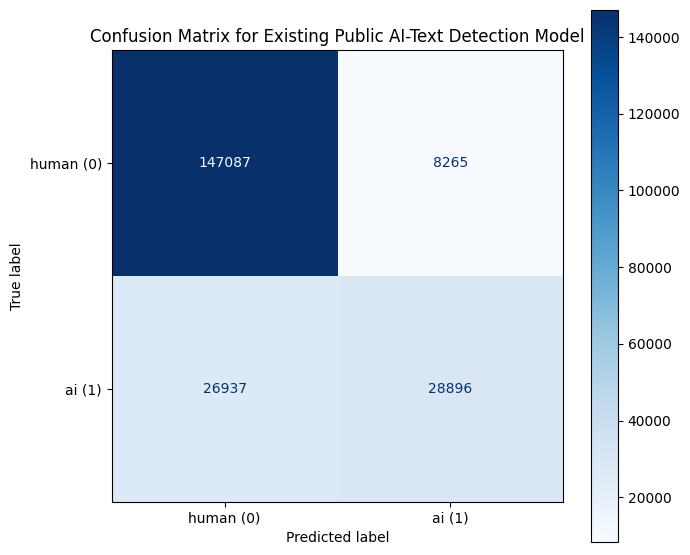

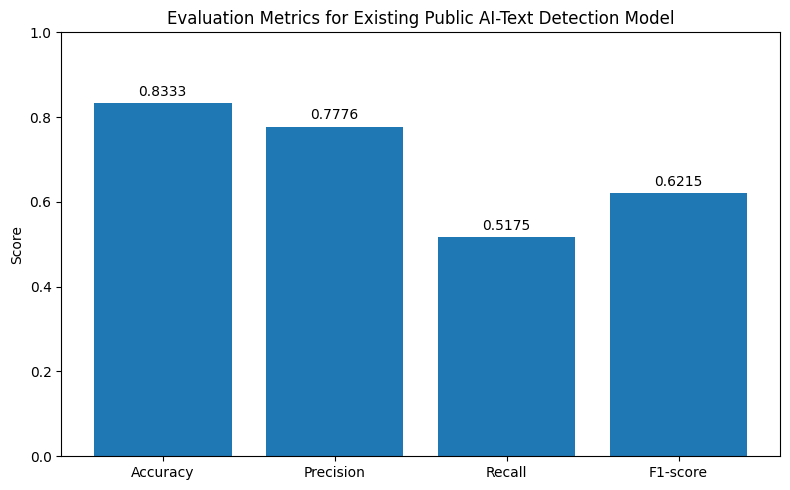

In [3]:
import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =========================
# 1. Check current working directory
# =========================
print("Current working directory:", os.getcwd())

# =========================
# 2. Define test path
# =========================
test_path = "../data/splits/test.parquet"
print("Test exists:", os.path.exists(test_path))

# =========================
# 3. Load shared test split
# =========================
test_df = pd.read_parquet(test_path)

print("\nTest shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())

print("\nTest label distribution:")
print(test_df["label"].value_counts().sort_index())

# =========================
# 4. Device setting
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("\nUsing device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("CUDA is not available. Running on CPU.")

# =========================
# 5. Load existing public AI-text detection model
# =========================
MODEL_NAME = "Hello-SimpleAI/chatgpt-detector-roberta"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

print("\nLoaded model:", MODEL_NAME)
print("id2label:", model.config.id2label)
print("label2id:", model.config.label2id)
print("Model device:", next(model.parameters()).device)

# =========================
# 6. Prepare test data
# Label convention:
# 0 = human-written
# 1 = AI-generated
# =========================
test_texts = test_df["text"].astype(str).tolist()
y_true = test_df["label"].astype(int).tolist()

# =========================
# 7. Prediction function
# =========================
def predict_in_batches(texts, tokenizer, model, device, batch_size=16, max_length=256):
    all_preds = []
    all_probs = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=max_length,
            return_tensors="pt"
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        if i == 0:
            print("Input device:", inputs["input_ids"].device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    return np.array(all_preds), np.array(all_probs)

# =========================
# 8. Run prediction on shared test split
# =========================
y_pred, y_prob = predict_in_batches(
    test_texts,
    tokenizer,
    model,
    device,
    batch_size=16,
    max_length=256
)

print("\nUnique predicted labels before adjustment:", np.unique(y_pred))

# =========================
# 9. IMPORTANT:
# Check label direction manually.
# Dataset labels:
# 0 = human-written
# 1 = AI-generated
#
# If the model label direction is reversed, uncomment the two lines below.
# =========================
# y_pred = 1 - y_pred
# y_prob = y_prob[:, ::-1]

# =========================
# 10. Evaluation
# =========================
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="binary", zero_division=0)
recall = recall_score(y_true, y_pred, average="binary", zero_division=0)
f1 = f1_score(y_true, y_pred, average="binary", zero_division=0)

print("\nExisting Public AI-Text Detection Model Results (Shared Test Set)")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, digits=4, zero_division=0))

# =========================
# 11. Save compact predictions
# =========================
results_df = pd.DataFrame({
    "sample_id": range(len(y_true)),
    "y_true": y_true,
    "y_pred": y_pred,
    "prob_ai": y_prob[:, 1]
})

output_path = "existing_model_test_predictions_compact.csv"
results_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("\nSaved predictions to:", output_path)

# =========================
# 12. Save metrics
# =========================
metrics = {
    "Model": "Model 02 Existing Public AI Detector",
    "Accuracy": float(accuracy),
    "Precision": float(precision),
    "Recall": float(recall),
    "F1-score": float(f1)
}

metrics_output_path = "existing_model_test_metrics.json"
with open(metrics_output_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

print("Saved metrics to:", metrics_output_path)

# =========================
# 13. Quick manual inspection
# =========================
sample_check = pd.DataFrame({
    "sample_id": range(min(10, len(test_df))),
    "true_label": y_true[:10],
    "pred_label": y_pred[:10],
    "prob_ai": y_prob[:10, 1]
})

print("\nSample predictions:")
print(sample_check)

# =========================
# 14. Confusion matrix
# =========================
cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

# =========================
# 15. Plot confusion matrix
# =========================
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["human (0)", "ai (1)"]
)
disp.plot(cmap="Blues", values_format="d", ax=ax)
ax.set_title("Confusion Matrix for Existing Public AI-Text Detection Model")
plt.tight_layout()
plt.show()

# =========================
# 16. Plot evaluation metrics
# =========================
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
metric_values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Evaluation Metrics for Existing Public AI-Text Detection Model")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()